In [1]:
import sns
# importamos wget y las librerías que nos faltan
from wget import download
from os import path
import pandas as pd

# descargamos la base de datos
if not path.exists("movies.csv"):
  download("https://ignaciorlando.github.io/datasets/data-science/movies.csv")
else:
  print("No vamos a bajar el archivo de Kaggle porque ya existe!")

In [82]:
import pandas as pd
df = pd.read_csv("movies.csv")
df.head()

,MOVIES,YEAR,GENRE,RATING,ONE-LINE,STARS,VOTES,RunTime,Gross
0,Blood Red Sky,(2021),"\nAction, Horror, Thriller",6.1,\nA woman with a mysterious illness is forced ...,\n Director:\nPeter Thorwarth\n| \n Star...,"21,062",121.0,NaN
1,Masters of the Universe: Revelation,(2021– ),"\nAnimation, Action, Adventure",5.0,\nThe war for Eternia begins again in what may...,"\n \n Stars:\nChris Wood, \nSara...","17,870",25.0,NaN
2,The Walking Dead,(2010–2022),"\nDrama, Horror, Thriller",8.2,\nSheriff Deputy Rick Grimes wakes up from a c...,"\n \n Stars:\nAndrew Lincoln, \n...","885,805",44.0,NaN
3,Rick and Morty,(2013– ),"\nAnimation, Adventure, Comedy",9.2,\nAn animated series that follows the exploits...,"\n \n Stars:\nJustin Roiland, \n...","414,849",23.0,NaN
4,Army of Thieves,(2021),"\nAction, Crime, Horror",NaN,"\nA prequel, set before the events of Army of ...",\n Director:\nMatthias Schweighöfer\n| \n ...,NaN,NaN,NaN


## Valores nulos

In [70]:
df.isna().sum()

MOVIES         0
YEAR         644
GENRE         80
RATING      1820
ONE-LINE       0
STARS          0
VOTES       1820
RunTime     2958
Gross       9539
dtype: int64

In [87]:
df["Gross"].value_counts()

Gross
10000.0       22
20000.0       16
0.0           15
30000.0       10
40000.0        9
              ..
210000.0       1
2830000.0      1
32240000.0     1
240000.0       1
10400000.0     1
Name: count, Length: 332, dtype: int64

## Elaboracion (D)
* Gross a float
* RunTime a float
* Tipos de variable
* Limpiar celdas

In [83]:

if 'Gross' in df.columns and df['Gross'].dtype == 'O':
    df['Gross'] = df['Gross'].str.replace(',', '').astype(float)
if 'RunTime' in df.columns and df['RunTime'].dtype == 'O':
    df['RunTime'] = df['RunTime'].str.replace(' min', '').astype(float)
if 'YEAR' in df.columns and df['YEAR'].dtype == 'O':
    df['YEAR'] = df['YEAR'].str.extract(r'(\d{4})').astype(float)


In [86]:
df.head()

,MOVIES,YEAR,GENRE,RATING,ONE-LINE,STARS,VOTES,RunTime,Gross
0,Blood Red Sky,(2021),"Action, Horror, Thriller",6.1,A woman with a mysterious illness is forced i...,Director: Peter Thorwarth | Stars: P...,21062.0,121.0,NaN
1,Masters of the Universe: Revelation,(2021– ),"Animation, Action, Adventure",5.0,The war for Eternia begins again in what may ...,"Stars: Chris Wood, Sarah Mi...",17870.0,25.0,NaN
2,The Walking Dead,(2010–2022),"Drama, Horror, Thriller",8.2,Sheriff Deputy Rick Grimes wakes up from a co...,"Stars: Andrew Lincoln, Norm...",885805.0,44.0,NaN
3,Rick and Morty,(2013– ),"Animation, Adventure, Comedy",9.2,An animated series that follows the exploits ...,"Stars: Justin Roiland, Chri...",414849.0,23.0,NaN
4,Army of Thieves,(2021),"Action, Crime, Horror",NaN,"A prequel, set before the events of Army of t...",Director: Matthias Schweighöfer | St...,NaN,NaN,NaN


In [95]:
import numpy as np
columnas = ["GENRE","ONE-LINE","STARS"]
for col in columnas:
    for col in df:
        df[col] = df[col].astype(str).str.replace('\n', ' ', regex=False)


# Lo pasa a numerico
df['RATING'] = pd.to_numeric(df['RATING'], errors='coerce')
df['VOTES'] = pd.to_numeric(df['VOTES'].str.replace(',', ''), errors='coerce')
df['RunTime'] = pd.to_numeric(df['RunTime'].str.replace(' min', ''), errors='coerce')

# 1. Limpiamos el símbolo de dólar y las comas
df['Gross'] = df['Gross'].astype(str).str.replace('$', '', regex=False).str.replace(',', '.', regex=False)

# 2. Detectamos cuáles tienen la 'M' (millones), se la quitamos y convertimos a número
es_millon = df['Gross'].str.contains('M', na=False)
df['Gross'] = df['Gross'].str.replace('M', '', regex=False)

# 3. Convertimos a numérico y multiplicamos por un millón los que correspondían
df['Gross'] = pd.to_numeric(df['Gross'], errors='coerce')
df.loc[es_millon, 'Gross'] *= 1_000_000

import pandas as pd

# 1. Crear una columna que indique si es serie (si contiene un guion '–')
df['IS_SERIES'] = df['YEAR'].str.contains('–', regex=False)

# 2. Extraer el año de inicio (los primeros 4 dígitos que aparecen en el texto) y pasarlo a numérico
df['YEAR_START'] = df['YEAR'].str.extract(r'(\d{4})').astype(float)

# (Opcional) Si quieres reemplazar la columna original YEAR por el año numérico limpio:
df['YEAR'] = df['YEAR_START']

In [115]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MOVIES      9999 non-null   str    
 1   YEAR        9251 non-null   float64
 2   GENRE       9919 non-null   str    
 3   RATING      8179 non-null   float64
 4   ONE-LINE    9999 non-null   str    
 5   STARS       9999 non-null   str    
 6   VOTES       8179 non-null   float64
 7   RunTime     7041 non-null   float64
 8   Gross       460 non-null    float64
 9   IS_SERIES   9999 non-null   bool   
 10  YEAR_START  9251 non-null   float64
 11  DECADE      9251 non-null   float64
 12  STARS_STR   9999 non-null   str    
 13  DIRECTOR    5356 non-null   str    
dtypes: bool(1), float64(7), str(6)
memory usage: 1.0 MB


# Hipótesis: Mejores películas (Público) = Mejores recaudaciones

C:\Users\mateo\AppData\Local\Temp\ipykernel_6500\1431689182.py:18: DeprecationWarning: Please import `pearsonr` from the `scipy.stats` namespace; the `scipy.stats.stats` namespace is deprecated and will be removed in SciPy 2.0.0.
  coeficiente_correlacion, _ = stats.pearsonr(df[variable_1], df[variable_2])


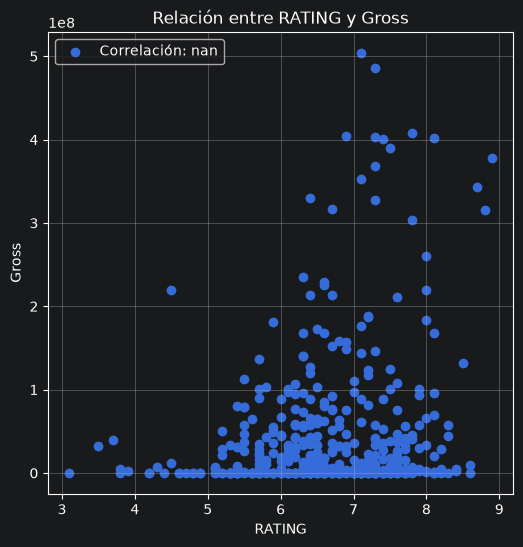

In [97]:
from scipy.stats import stats
import matplotlib.pyplot as plt

variable_1 = "RATING"
variable_2 = "Gross"
# en clase, mostrar también este ejemplo
#variable_1 = "CHAS"
#variable_2 = "NOX"

# creamos el scatter plot
plt.figure(figsize=(6, 6))  # con esta línea podemos ajustar el tamaño de la gráfica
plt.scatter(df[variable_1], df[variable_2])
plt.xlabel(variable_1)
plt.ylabel(variable_2)
plt.title("Relación entre {} y {}".format(variable_1, variable_2))

# calcular la correlación de Pearson usando SciPy
coeficiente_correlacion, _ = stats.pearsonr(df[variable_1], df[variable_2])
# agregar la leyenda con el valor del coeficiente de correlación
plt.legend([f"Correlación: {coeficiente_correlacion:.4f}"], loc="upper left")

# Mostrar el gráfico
plt.grid(True)
plt.show()
# Si es menor a 0.5, la hipótesis del preconcepto se debilita.

# Las películas de los últimos años tienen mayor duración

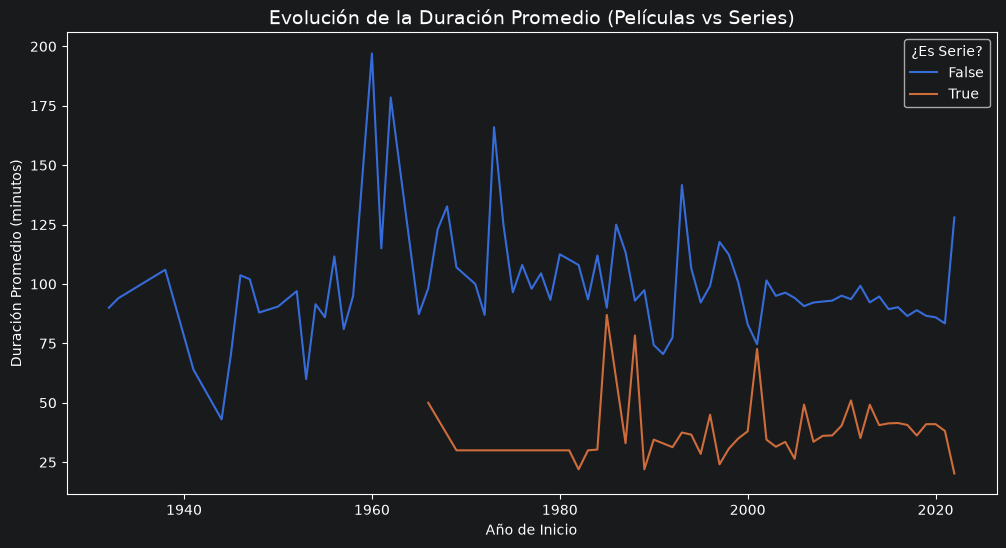

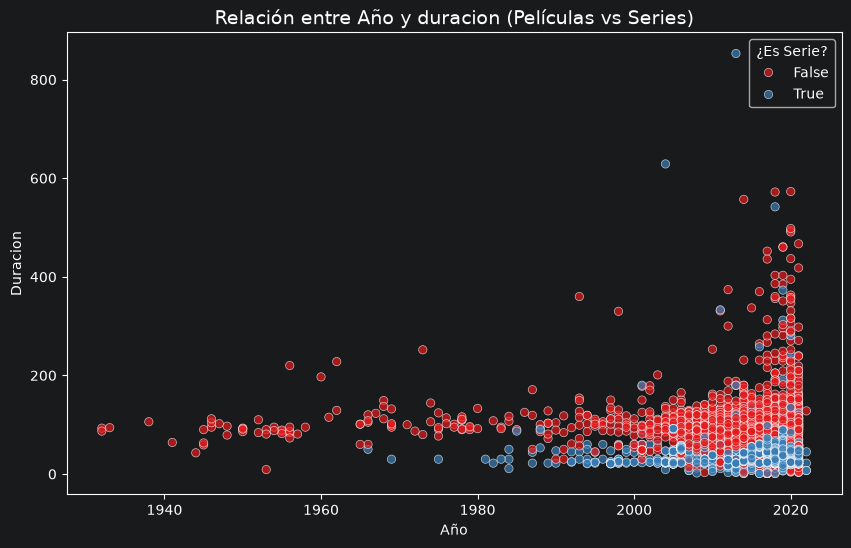

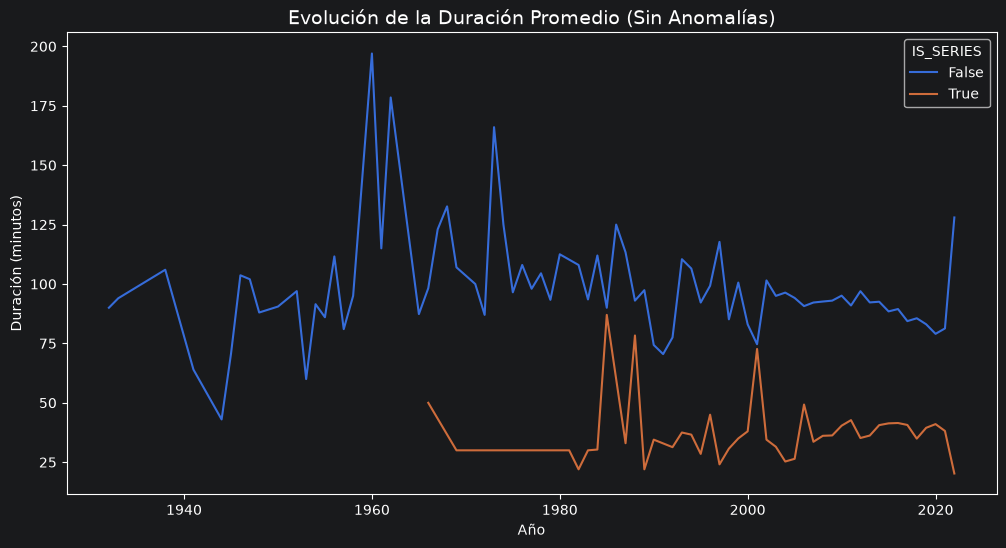

C:\Users\mateo\AppData\Local\Temp\ipykernel_6500\1802129331.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


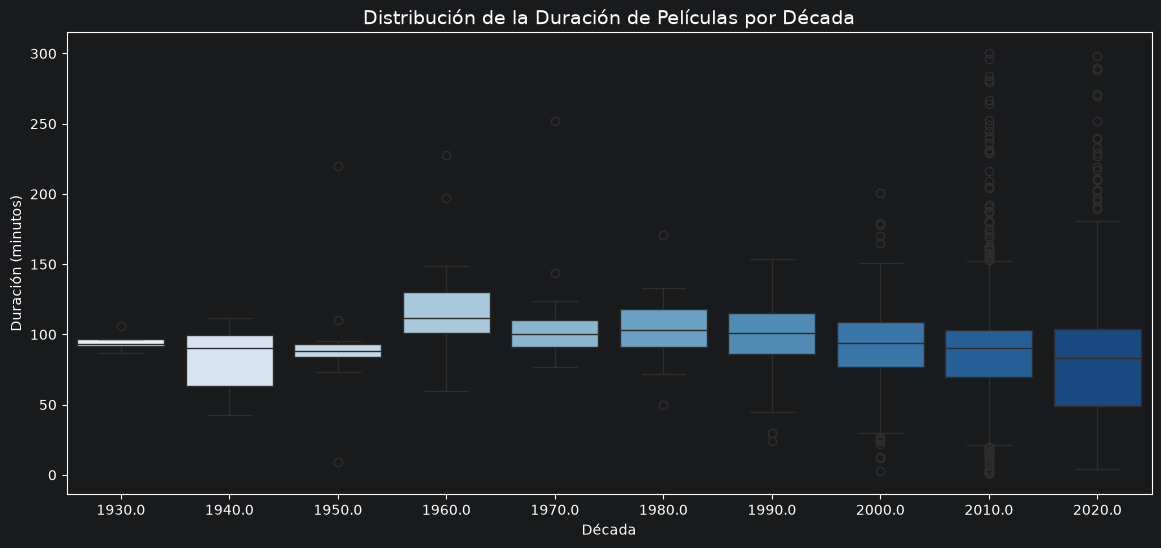

In [104]:
from scipy.stats import stats
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df,
    x='YEAR',
    y='RunTime',
    hue='IS_SERIES',  # Separa las líneas para películas y series
    errorbar=None     # Quita la banda de confianza para ver la línea limpia
)
plt.title('Evolución de la Duración Promedio (Películas vs Series)', fontsize=14)
plt.xlabel('Año de Inicio')
plt.ylabel('Duración Promedio (minutos)')
plt.legend(title='¿Es Serie?')
plt.show()




plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='YEAR',
    y='RunTime',
    hue='IS_SERIES',   # Colorea diferente si es serie o película
    alpha=0.7,
    palette='Set1'
)
plt.title('Relación entre Año y duracion (Películas vs Series)', fontsize=14)
plt.xlabel('Año')
plt.ylabel('Duracion')
plt.legend(title='¿Es Serie?')
plt.show()


# 1. Filtramos valores lógicos de duración (ej: películas que duran entre 1 y 300 minutos)
df_filtrado = df[(df['RunTime'] > 0) & (df['RunTime'] <= 300)].copy()

# 2. Gráfico de líneas limpio por año y separado por tipo
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df_filtrado,
    x='YEAR',
    y='RunTime',
    hue='IS_SERIES',
    errorbar=None
)
plt.title('Evolución de la Duración Promedio (Sin Anomalías)', fontsize=14)
plt.xlabel('Año')
plt.ylabel('Duración (minutos)')
plt.show()

# 1. Creamos una columna de década
df['DECADE'] = (df['YEAR'] // 10) * 10

# 2. Filtramos valores absurdos mayores a 300 minutos para limpiar la visualización del boxplot
df_limpio = df[df['RunTime'] <= 300]

plt.figure(figsize=(14, 6))
sns.boxplot(
    data=df_limpio[df_limpio['IS_SERIES'] == False], # Analizamos solo películas por ejemplo
    x='DECADE',
    y='RunTime',
    palette='Blues'
)
plt.title('Distribución de la Duración de Películas por Década', fontsize=14)
plt.xlabel('Década')
plt.ylabel('Duración (minutos)')
plt.show()

### Se puede observar que mediante pasa los años pero sus distribuciones no han variado, siguen estando rondando sobre los 100 minutos de media

# G: La cantidad de votos (popularidad) influye más en la recaudación que el puntaje (Rating).

In [106]:
corr_votos_gross = df['VOTES'].corr(df['Gross'])
print(f"Correlación Votos vs Recaudación: {corr_votos_gross:.2f}")

Correlación Votos vs Recaudación: 0.65


## El género Drama obtiene calificaciones (Ratings) significativamente más altas que el género Acción o Terror

In [117]:
import pandas as pd
df['RATING'] = pd.to_numeric(df['RATING'], errors='coerce')

rating_drama = df[df['GENRE'].str.contains('Drama', case=False, na=False)]['RATING'].mean()
rating_accion = df[df['GENRE'].str.contains('Action', case=False, na=False)]['RATING'].mean()
rating_terror= df[df['GENRE'].str.contains('Horror', case=False, na=False)]['RATING'].mean()

print(f"Rating Promedio - Drama: {rating_drama:.2f}")
print(f"Rating Promedio - Acción: {rating_accion:.2f}")
print(f"Rating Promedio - Terror: {rating_terror:.2f}")

Rating Promedio - Drama: 7.09
Rating Promedio - Acción: 7.10
Rating Promedio - Terror: 5.86


### Falsa, Los 3 generos se mantienen muy a la par entre Action y Drama pero Terror no esta tan abajo, con 1 punto de diferencia

## Las películas dirigidas por ciertos directores garantizan una alta recaudación independientemente de su calificación en IMDb

In [110]:
# 1. Asegurarnos de tratar la columna STARS como string y limpiar espacios
df['STARS_STR'] = df['STARS'].astype(str)

# 2. Extraer el nombre del director usando regex
# Busca la palabra "Director: " y captura todo lo que sigue hasta encontrar un " |" o el final de la línea
df['DIRECTOR'] = df['STARS_STR'].str.extract(r'Director:\s*([^|]+)', expand=False).str.strip()

# 3. Verificamos que se haya extraído correctamente
print(df[['STARS_STR', 'DIRECTOR']].head(5))

                                           STARS_STR               DIRECTOR
0       Director: Peter Thorwarth |      Stars: P...        Peter Thorwarth
1                    Stars: Chris Wood,  Sarah Mi...                    NaN
2                    Stars: Andrew Lincoln,  Norm...                    NaN
3                    Stars: Justin Roiland,  Chri...                    NaN
4       Director: Matthias Schweighöfer |      St...  Matthias Schweighöfer


In [114]:
# Agrupamos por director (requiere que exista la columna 'Director')
directores_taquilleros = df.groupby('DIRECTOR').agg({'Gross':'sum', 'RATING':'mean', 'DIRECTOR':'count'})
# Filtramos directores con al menos 3 películas
directores_taquilleros = directores_taquilleros[directores_taquilleros['Director'] >= 3]
top_10_recaudadores = directores_taquilleros.sort_values(by='Gross', ascending=False).head(10)
print("\nTop 10 Directores por Recaudación Total:")
print(top_10_recaudadores[['Gross', 'RATING']])


Top 10 Directores por Recaudación Total:
                            Gross    RATING
DIRECTOR                                   
Peter Jackson        1.338940e+09  8.550000
Steven Spielberg     9.734400e+08  7.475000
Jake Kasdan          7.213500e+08  6.800000
Sam Raimi            6.572600e+08  6.666667
Zack Snyder          5.409700e+08  6.600000
Olivier Megaton      2.657800e+08  5.600000
Robert Luketic       2.325000e+08  6.066667
Peter Berg           1.865300e+08  6.933333
Jordan Vogt-Roberts  1.680500e+08  6.650000
David Fincher        1.677700e+08  7.500000


### Valores Unicos

In [118]:
unicos_generos = df['GENRE'].unique()
print(unicos_generos)

<StringArray>
[    ' Action, Horror, Thriller            ',
 ' Animation, Action, Adventure            ',
      ' Drama, Horror, Thriller            ',
 ' Animation, Adventure, Comedy            ',
        ' Action, Crime, Horror            ',
         ' Action, Crime, Drama            ',
               ' Drama, Romance            ',
        ' Crime, Drama, Mystery            ',
                       ' Comedy            ',
  ' Action, Adventure, Thriller            ',
 ...
    ' Comedy, Mystery, Thriller            ',
  ' Documentary, History, Music            ',
 ' Documentary, Family, History            ',
   ' Documentary, Action, Crime            ',
               ' Short, History            ',
            ' Short, Reality-TV            ',
                ' Short, Action            ',
      ' Biography, Family, News            ',
             ' News, Reality-TV            ',
             ' Talk-Show, Sport            ']
Length: 511, dtype: str
